<a href="https://colab.research.google.com/github/mihaipopa15/pi-bia/blob/main/pilab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
#ex1

In [68]:
import torch
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

In [69]:
def synthetic_data(w, b, num_examples):
    """Generate y = Xw + b + noise."""
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = X @ w + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape(-1, 1)

In [70]:
true_w = torch.tensor([1.0])
true_b = torch.tensor([-1.0])

# pentru ca avem 60 * 1
features, labels = synthetic_data(true_w, true_b, 60)

In [71]:
print('Features:', features[0], '\nLabel:', labels[0])

Features: tensor([1.9269]) 
Label: tensor([0.9289])


In [72]:
# `nn` is an abbreviation for neural networks
from torch import nn

net = nn.Sequential(nn.Linear(1, 1))    # one input, one output

In [73]:
# set the weights and bias to 1
net[0].weight.data.fill_(1)
net[0].bias.data.fill_(1)

tensor([1.])

In [74]:
# implement the mean squared error function

def loss_function(y_pred, y):
  return torch.mean((y_pred - y) ** 2)

In [75]:
batch_size = 10
lr = 0.05
num_iterations = 25

In [76]:
def load_array(data_arrays, batch_size, is_train=True):
    """Construct a PyTorch data iterator."""
    dataset = torch.utils.data.TensorDataset(*data_arrays)
    return torch.utils.data.DataLoader(dataset, batch_size, shuffle=is_train)

In [77]:
data_iter = load_array((features, labels), batch_size)

In [79]:
num_epochs = 25

for epoch in range(num_epochs):
  for X, y in data_iter:
    l = loss_function(net(X), y)
    l.backward()

    net[0].weight.data -= lr * net[0].weight.grad.data
    net[0].bias.data -= lr * net[0].bias.grad.data

    net[0].weight.grad.data.zero_()
    net[0].bias.grad.data.zero_()

  l = loss_function(net(features), labels)
  print(f'epoch {epoch + 1}, loss {l:f}')

epoch 1, loss 0.010211
epoch 2, loss 0.003565
epoch 3, loss 0.001311
epoch 4, loss 0.000525
epoch 5, loss 0.000255
epoch 6, loss 0.000155
epoch 7, loss 0.000122
epoch 8, loss 0.000110
epoch 9, loss 0.000106
epoch 10, loss 0.000105
epoch 11, loss 0.000104
epoch 12, loss 0.000104
epoch 13, loss 0.000104
epoch 14, loss 0.000104
epoch 15, loss 0.000104
epoch 16, loss 0.000104
epoch 17, loss 0.000104
epoch 18, loss 0.000104
epoch 19, loss 0.000104
epoch 20, loss 0.000104
epoch 21, loss 0.000104
epoch 22, loss 0.000104
epoch 23, loss 0.000104
epoch 24, loss 0.000104
epoch 25, loss 0.000104


In [32]:
import torchvision
from torchvision import transforms
import torch
from torch import nn

In [33]:
def load_data_fashion_mnist(batch_size, resize=None):
    """Download the Fashion-MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.MNIST(
        root="../data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.MNIST(
        root="../data", train=False, transform=trans, download=True)
    mnist_train, mnist_val = torch.utils.data.random_split(mnist_train, [30000, 30000],
                                                           generator=torch.Generator().manual_seed(42))
    return (torch.utils.data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=2))

In [34]:
batch_size = 100
train_iter, val_iter, test_iter = load_data_fashion_mnist(batch_size)

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.3MB/s]


In [35]:
net = nn.Sequential(nn.Flatten(), nn.Linear((28 * 28), 10))

In [36]:
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.constant_(m.weight, 1)

net.apply(init_weights)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)

In [37]:
loss = nn.CrossEntropyLoss()

In [38]:
lr = 0.15
optimizer = torch.optim.SGD(net.parameters(), lr=lr)

In [39]:
def evaluate_accuracy(net, data_iter):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100

In [40]:
def train_epoch(net, train_iter, loss, optimizer):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100

In [41]:
def train(net, train_iter, val_iter, loss, num_epochs, optimizer):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [42]:
num_epochs = 15
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, loss, num_epochs, optimizer)

Epoch 1, Train loss 0.58, Train accuracy 85.98, Validation loss 0.41, Validation accuracy 88.87
Epoch 2, Train loss 0.37, Train accuracy 89.77, Validation loss 0.37, Validation accuracy 89.73
Epoch 3, Train loss 0.34, Train accuracy 90.60, Validation loss 0.35, Validation accuracy 90.31
Epoch 4, Train loss 0.32, Train accuracy 91.10, Validation loss 0.34, Validation accuracy 90.61
Epoch 5, Train loss 0.31, Train accuracy 91.37, Validation loss 0.33, Validation accuracy 90.81
Epoch 6, Train loss 0.30, Train accuracy 91.68, Validation loss 0.32, Validation accuracy 90.97
Epoch 7, Train loss 0.29, Train accuracy 91.79, Validation loss 0.32, Validation accuracy 91.05
Epoch 8, Train loss 0.29, Train accuracy 92.02, Validation loss 0.32, Validation accuracy 91.15
Epoch 9, Train loss 0.28, Train accuracy 92.12, Validation loss 0.31, Validation accuracy 91.06
Epoch 10, Train loss 0.28, Train accuracy 92.28, Validation loss 0.31, Validation accuracy 91.07
Epoch 11, Train loss 0.28, Train accura

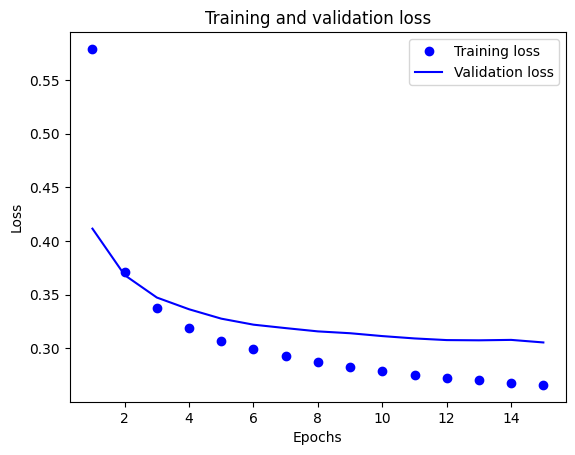

In [43]:
def plot_loss(train_loss_all, val_loss_all):
    epochs = range(1, len(train_loss_all) + 1)
    plt.plot(epochs, train_loss_all, 'bo', label='Training loss')
    plt.plot(epochs, val_loss_all, 'b', label='Validation loss')
    plt.title('Training and validation loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_loss(train_loss_all, val_loss_all)

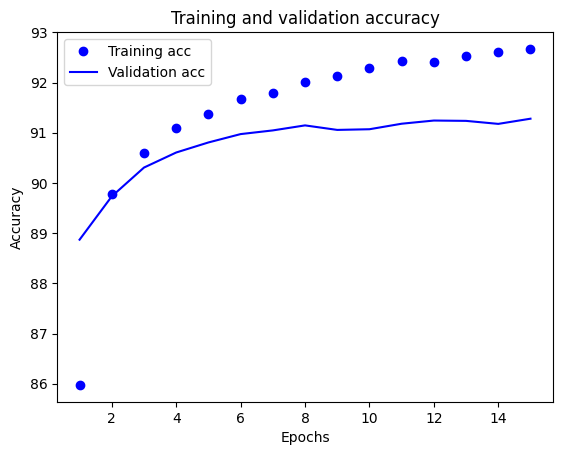

In [44]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)

In [45]:
test_loss, test_acc = evaluate_accuracy(net, test_iter)
print(f'Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}')

Test loss 0.28, Test accuracy 92.15


In [46]:
def get_fashion_mnist_labels(labels):
    """Return text labels for the Fashion-MNIST dataset."""
    text_labels = ['0','1', '2', '3', '4', '5', '6', '7', '8', '9']
    return [text_labels[int(i)] for i in labels]

In [47]:
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    """Plot a list of images."""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    plt.tight_layout()
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # Tensor Image
            ax.imshow(img.numpy())
        else:
            # PIL Image
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes


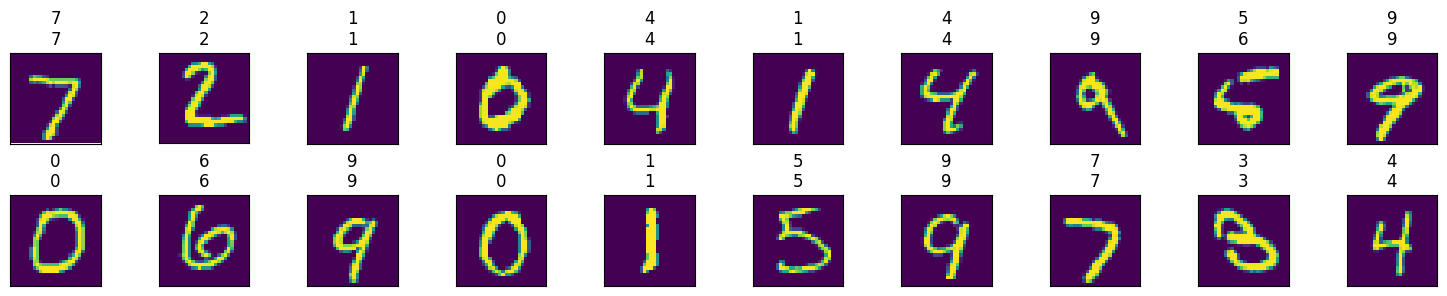

In [48]:
def predict(net, test_iter, n=20):
    """Predict labels."""
    for X, y in test_iter:
        break
    trues = get_fashion_mnist_labels(y)
    preds = get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true +'\n' + pred for true, pred in zip(trues, preds)]
    show_images(X[0:n].reshape((n, 28, 28)), 2, int(n/2), titles=titles[0:n])

predict(net, test_iter)

In [ ]:
#ex3

In [49]:

import torchvision
from torchvision import transforms
import torch
from torch import nn

In [50]:
def load_data_mnist(batch_size, resize=None):
    """Download the MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.MNIST(
        root="../data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.MNIST(
        root="../data", train=False, transform=trans, download=True)
    mnist_train, mnist_val = torch.utils.data.random_split(mnist_train, [30000, 30000],
                                                           generator=torch.Generator().manual_seed(42))
    return (torch.utils.data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=2))

In [51]:
batch_size = 100
train_iter, val_iter, test_iter = load_data_mnist(batch_size)

In [52]:
net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.Tanh(),
    nn.Dropout(0.4),
    nn.Linear(256, 256),
    nn.Tanh(),
    nn.Dropout(0.4),
    nn.Linear(256, 10)
)

In [53]:
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)
        nn.init.constant_(m.bias, 0)

net.apply(init_weights)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): Tanh()
  (3): Dropout(p=0.4, inplace=False)
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): Tanh()
  (6): Dropout(p=0.4, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)

In [54]:
loss = nn.CrossEntropyLoss()

In [55]:
lr = 0.15
optimizer = torch.optim.SGD(net.parameters(), lr=lr)

In [56]:
def evaluate_accuracy(net, data_iter):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100

In [57]:
def train_epoch(net, train_iter, loss, optimizer):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100

In [58]:
def train(net, train_iter, val_iter, loss, num_epochs, optimizer):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [59]:
num_epochs = 15
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, loss, num_epochs, optimizer)

Epoch 1, Train loss 0.51, Train accuracy 84.52, Validation loss 0.33, Validation accuracy 90.53
Epoch 2, Train loss 0.36, Train accuracy 89.14, Validation loss 0.30, Validation accuracy 91.13
Epoch 3, Train loss 0.32, Train accuracy 90.40, Validation loss 0.27, Validation accuracy 92.18
Epoch 4, Train loss 0.29, Train accuracy 91.11, Validation loss 0.26, Validation accuracy 92.43
Epoch 5, Train loss 0.27, Train accuracy 91.80, Validation loss 0.23, Validation accuracy 93.27
Epoch 6, Train loss 0.26, Train accuracy 92.29, Validation loss 0.23, Validation accuracy 93.31
Epoch 7, Train loss 0.24, Train accuracy 92.78, Validation loss 0.22, Validation accuracy 93.43
Epoch 8, Train loss 0.23, Train accuracy 93.08, Validation loss 0.20, Validation accuracy 94.26
Epoch 9, Train loss 0.22, Train accuracy 93.52, Validation loss 0.19, Validation accuracy 94.36
Epoch 10, Train loss 0.21, Train accuracy 93.82, Validation loss 0.18, Validation accuracy 94.58
Epoch 11, Train loss 0.20, Train accura

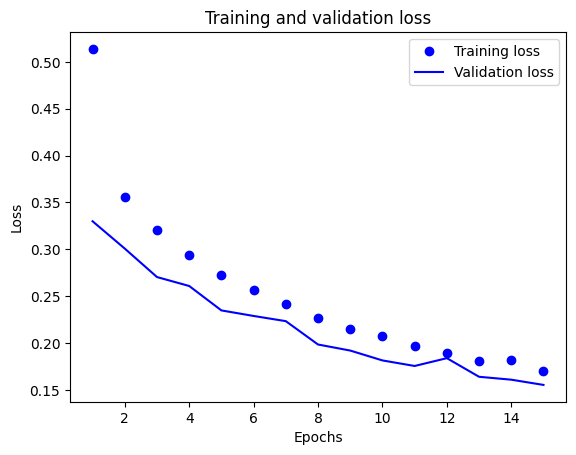

In [60]:
def plot_loss(train_loss_all, val_loss_all):
    epochs = range(1, len(train_loss_all) + 1)
    plt.plot(epochs, train_loss_all, 'bo', label='Training loss')
    plt.plot(epochs, val_loss_all, 'b', label='Validation loss')
    plt.title('Training and validation loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_loss(train_loss_all, val_loss_all)

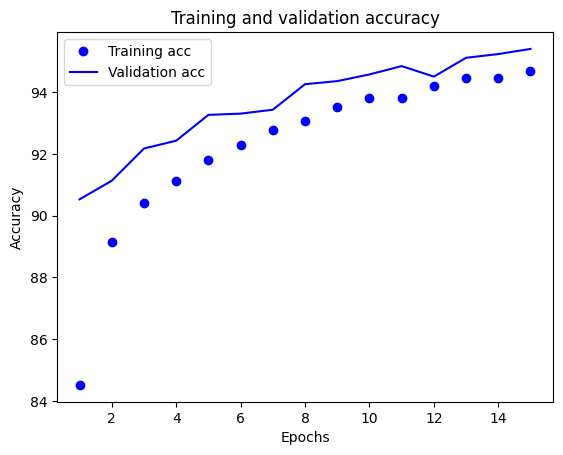

In [61]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)

In [62]:
test_loss, test_acc = evaluate_accuracy(net, test_iter)
print(f'Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}')

Test loss 0.14, Test accuracy 95.77


In [63]:
def get_fashion_mnist_labels(labels):
    """Return text labels for the Fashion-MNIST dataset."""
    text_labels = ['0','1', '2', '3', '4', '5', '6', '7', '8', '9']
    return [text_labels[int(i)] for i in labels]

In [64]:
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    """Plot a list of images."""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    plt.tight_layout()
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # Tensor Image
            ax.imshow(img.numpy())
        else:
            # PIL Image
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes

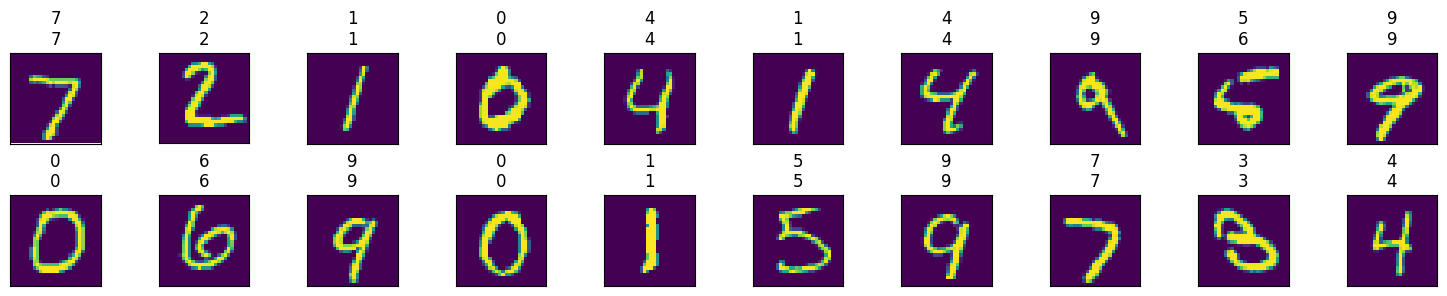

In [65]:
def predict(net, test_iter, n=20):
    """Predict labels."""
    for X, y in test_iter:
        break
    trues = get_fashion_mnist_labels(y)
    preds = get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true +'\n' + pred for true, pred in zip(trues, preds)]
    show_images(X[0:n].reshape((n, 28, 28)), 2, int(n/2), titles=titles[0:n])

predict(net, test_iter)